# ✈️ Airline Satisfaction: Flight Distance as a Route ID + Original-Data Teacher (Private 0.96140)

This notebook explains the features that took my solution from a **0.95954 → 0.96140** Private LB
in Playground Series S6E10, and trains the best **single LightGBM** end to end (about 10 minutes on a Kaggle CPU).

**TL;DR — what worked (5-fold CV AUC of a single LightGBM):**

| Step | Idea | CV | Δ CV | Public | Private |
|---|---|---|---|---|---|
| 0 | Raw 21 features | 0.95888 | | 0.95849 | 0.95954 |
| 1 | + Target encoding computed on the **original dataset** | 0.95960 | +0.00072 | 0.95918 | 0.96022 |
| 2 | + **Flight Distance as a route ID** (count + in-fold TE) | 0.96024 | +0.00064 | – | – |
| 3 | + **Route profile** (per-route means of other columns) | 0.96049 | +0.00025 | 0.96021 | 0.96094 |
| 4 | + **Teacher model** trained on the original dataset | **0.96074** | +0.00025 | 0.96023 | **0.96115** |

Then, on the same features (not trained in this notebook, see the last section):

| Model | CV | Public | Private |
|---|---|---|---|
| Rank average of LightGBM / XGBoost / CatBoost (5-fold) | 0.96101 | 0.96053 | 0.96129 |
| Same, trained with 10 folds | 0.96116 | 0.96057 | 0.96137 |
| + CatBoost with 39 rating × context crosses (final) | **0.96121** | 0.96058 | **0.96140** |

CV tracked the Private LB very well (CV − Private ≈ −0.0002 for every step), so all decisions were made on CV only.

Many of these ideas came from this competition's discussions — credits are linked in each section. 🙏

## 1. Setup

In [1]:
import os
import re
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, StratifiedKFold

# Kaggle: competition data + the original dataset added as input. Locally: the same files under DataSet/
if Path("/kaggle/input").exists():
    # the folder layout under /kaggle/input can change, so locate the files instead of hard-coding paths
    COMP_DIR = next(Path("/kaggle/input").rglob("sample_submission.csv")).parent
    ORIG_DIR = next(p.parent for p in Path("/kaggle/input").rglob("train.csv")
                    if "airline-passenger-satisfaction" in str(p))
else:
    COMP_DIR = Path("../DataSet")
    ORIG_DIR = COMP_DIR / "original"

TARGET = "satisfaction"
SEED = 42
N_SPLITS = 5
CAT_COLS = ["gender", "customer_type", "type_of_travel", "class"]
RATING_COLS = [
    "inflight_wifi_service", "departure_arrival_time_convenient", "ease_of_online_booking",
    "gate_location", "food_and_drink", "online_boarding", "seat_comfort",
    "inflight_entertainment", "on_board_service", "leg_room_service",
    "baggage_handling", "checkin_service", "cleanliness",
]
ROUTE_KEY = "flight_distance"
print(COMP_DIR, ORIG_DIR, sep="\n")

..\DataSet
..\DataSet\original


## 2. Load data

* Column names are converted to snake_case so that every library accepts them.
* The original dataset ([Airline Passenger Satisfaction](https://www.kaggle.com/datasets/teejmahal20/airline-passenger-satisfaction),
  train + test = 129,880 rows) has one extra column, `Inflight service`, which is not in the competition data, so it is dropped.

In [2]:
def to_snake(name):
    return re.sub(r"[^0-9a-z]+", "_", name.lower()).strip("_")


train = pd.read_csv(COMP_DIR / "train.csv")
test = pd.read_csv(COMP_DIR / "test.csv")
orig = pd.concat([pd.read_csv(ORIG_DIR / f) for f in ("train.csv", "test.csv")], ignore_index=True)
for df in (train, test, orig):
    df.columns = [to_snake(c) for c in df.columns]
orig = orig.drop(columns=["unnamed_0", "id", "inflight_service"])

train[TARGET] = train[TARGET].astype(int)                     # True = satisfied
orig[TARGET] = (orig[TARGET] == "satisfied").astype(int)
for col in CAT_COLS:
    cats = sorted(set(train[col].dropna()) | set(test[col].dropna()))
    for df in (train, test, orig):
        df[col] = pd.Categorical(df[col], categories=cats)

BASE = [c for c in train.columns if c not in ("id", TARGET)]
print(f"train {train.shape}, test {test.shape}, original {orig.shape}")
print(f"satisfaction rate: train {train[TARGET].mean():.3f}, original {orig[TARGET].mean():.3f}")

train (699635, 23), test (299844, 22), original (129880, 22)
satisfaction rate: train 0.444, original 0.434


## 3. Three things I learned from EDA

### 3.1 A rating of 0 is "not applicable", not "worse than 1"

Satisfaction by rating value is U-shaped: passengers who gave **0** behave very differently from those who gave 1–3.
Tree models can split on 0 by themselves, so extra "is zero" flags did **not** help (CV −0.00017) —
but it matters for linear models / row-wise averages.

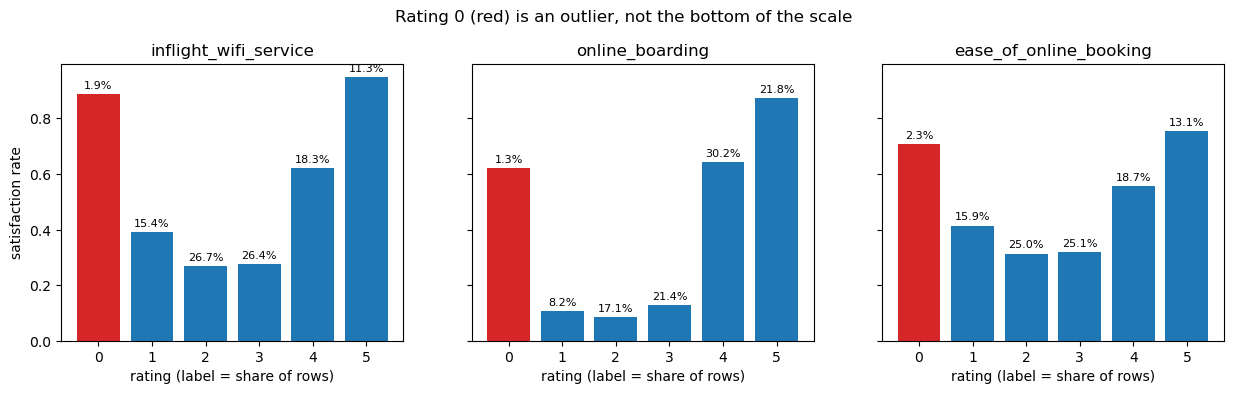

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, col in zip(axes, ["inflight_wifi_service", "online_boarding", "ease_of_online_booking"]):
    rate = train.groupby(col)[TARGET].mean()
    share = train[col].value_counts(normalize=True).sort_index()
    ax.bar(rate.index, rate.values, color=["#d62728"] + ["#1f77b4"] * (len(rate) - 1))
    for x, (r, s) in enumerate(zip(rate.values, share.values)):
        ax.text(rate.index[x], r + 0.02, f"{s:.1%}", ha="center", fontsize=8)
    ax.set_title(col)
    ax.set_xlabel("rating (label = share of rows)")
axes[0].set_ylabel("satisfaction rate")
plt.suptitle("Rating 0 (red) is an outlier, not the bottom of the scale", y=1.03)
plt.show()

### 3.2 Flight Distance behaves like a **route ID**

There are only **3,521 distinct values for ~1M rows** (train + test), so each value repeats many times (median 72 rows).
Passengers with the same distance share a very different mix of class, travel type and ratings —
so a distance is better treated as **"which route"** than as a number. (Credits: [#747742](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/747742), [#749007](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/749007), [#745908](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/745908))

rows: 999,479   distinct flight_distance values: 3,521
median rows per distance: 72


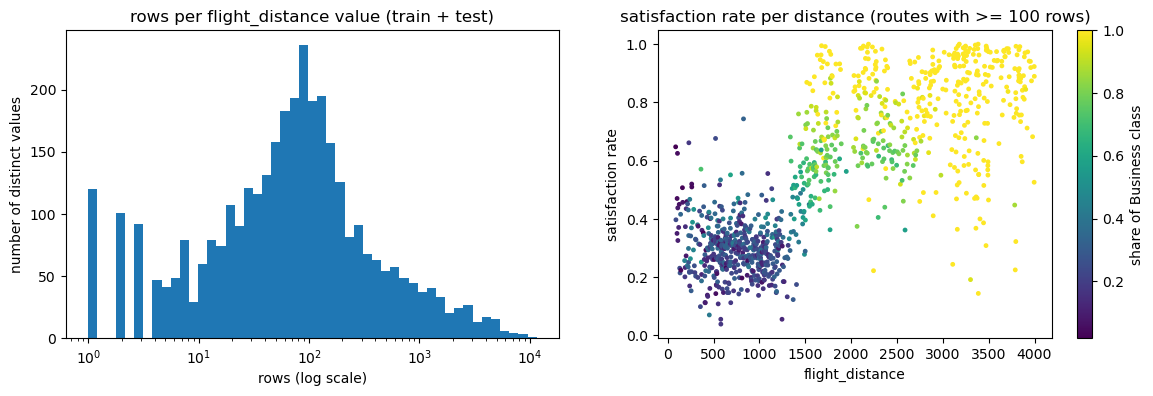

In [4]:
both = pd.concat([train, test], ignore_index=True)
counts = both[ROUTE_KEY].value_counts()
print(f"rows: {len(both):,}   distinct flight_distance values: {both[ROUTE_KEY].nunique():,}")
print(f"median rows per distance: {counts.median():.0f}")

route = train.groupby(ROUTE_KEY).agg(n=(TARGET, "size"), rate=(TARGET, "mean"),
                                     business=("class", lambda s: (s == "Business").mean()))
route = route[route["n"] >= 100]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(counts.values, bins=np.logspace(0, np.log10(counts.max()), 50))
axes[0].set_xscale("log")
axes[0].set_title("rows per flight_distance value (train + test)")
axes[0].set_xlabel("rows (log scale)")
axes[0].set_ylabel("number of distinct values")
sc = axes[1].scatter(route.index, route["rate"], c=route["business"], s=6, cmap="viridis")
axes[1].set_title("satisfaction rate per distance (routes with >= 100 rows)")
axes[1].set_xlabel("flight_distance")
axes[1].set_ylabel("satisfaction rate")
plt.colorbar(sc, ax=axes[1], label="share of Business class")
plt.show()

Neighbouring distances can have very different satisfaction rates — the "route" carries information that a smooth
numeric split cannot capture. This motivates three groups of route features (section 4.2).

### 3.3 The original dataset is close, but **not** the same distribution

Delays are much shorter in the competition data, while categories and ratings look alike.
Simply appending the original rows to the training data **hurt** (CV −0.00020), but using the original data as a
**source of features** helped a lot (sections 4.1 and 4.3).

In [5]:
summary = pd.DataFrame({
    "competition": [train["departure_delay_in_minutes"].eq(0).mean(), train["departure_delay_in_minutes"].mean(),
                    train["flight_distance"].mean(), train[TARGET].mean()],
    "original": [orig["departure_delay_in_minutes"].eq(0).mean(), orig["departure_delay_in_minutes"].mean(),
                 orig["flight_distance"].mean(), orig[TARGET].mean()],
}, index=["share of zero departure delay", "mean departure delay (min)", "mean flight distance", "satisfaction rate"])
summary.round(3)

,competition,original
share of zero departure delay,0.908,0.565
mean departure delay (min),1.176,14.714
mean flight distance,1353.779,1190.316
satisfaction rate,0.444,0.434


## 4. Features

### 4.1 Target encoding computed on the original dataset (+0.00072)

For every column and every value, add the satisfaction rate (and the count) of that value **in the original dataset**.
Because the original data is a separate dataset, this needs no out-of-fold handling — there is no leakage into the CV.
Values seen fewer than 20 times are set to NaN.

In [6]:
def add_original_te(df, cols, min_count=20):
    df = df.copy()
    for col in cols:
        stats = orig.groupby(orig[col].astype(str), observed=True)[TARGET].agg(["mean", "size"])
        key = df[col].astype(str)
        df[f"{col}_orig_te"] = key.map(stats["mean"].where(stats["size"] >= min_count)).astype(float)
        df[f"{col}_orig_cnt"] = key.map(stats["size"]).fillna(0).astype(float)
    return df

### 4.2 Route features (+0.00064, then +0.00025)

* **`fd_count`** — rows with the same distance (train + test, no labels).
* **`flight_distance_te`** — smoothed target encoding of the route, computed **inside each CV fold**
  (the training part uses an inner 5-fold split so a row never sees its own label; smoothing m = 10).
* **`fd_mean_*`** — the route's *profile*: mean of every rating, age, delay and the shares of
  Business class / Eco / business travel / loyal / female passengers (train + test, no labels).

I also tried the residuals "row value − route mean"; they made CV **worse** (−0.00026), probably feature dilution.

In [7]:
def add_route_features(train, test):
    both = pd.concat([train, test], ignore_index=True)
    counts = both[ROUTE_KEY].value_counts()

    src = both[RATING_COLS + ["age", "departure_delay_in_minutes"]].astype(float)
    src["is_business_class"] = (both["class"] == "Business").astype(float)
    src["is_eco_class"] = (both["class"] == "Eco").astype(float)
    src["is_business_travel"] = (both["type_of_travel"] == "Business travel").astype(float)
    src["is_loyal"] = (both["customer_type"] == "Loyal Customer").astype(float)
    src["is_female"] = (both["gender"] == "Female").astype(float)
    means = src.groupby(both[ROUTE_KEY]).mean().add_prefix("fd_mean_")

    out = []
    for df in (train, test):
        df = df.assign(fd_count=df[ROUTE_KEY].map(counts).astype(float))
        out.append(pd.concat([df, means.reindex(df[ROUTE_KEY]).set_index(df.index)], axis=1))
    return out


def smoothed_mean(key, y, prior, m):
    stats = y.groupby(key.values, observed=True).agg(["sum", "count"])
    return (stats["sum"] + m * prior) / (stats["count"] + m)


def add_fold_te(X_tr, y_tr, X_va, X_te, col=ROUTE_KEY, m=10.0, n_inner=5):
    """Target encoding inside one CV fold (validation/test use the whole training part, training uses inner folds)."""
    X_tr, X_va, X_te = X_tr.copy(), X_va.copy(), X_te.copy()
    prior = float(y_tr.mean())
    full = smoothed_mean(X_tr[col], y_tr, prior, m)
    X_va[f"{col}_te"] = X_va[col].map(full).fillna(prior).astype(float).values
    X_te[f"{col}_te"] = X_te[col].map(full).fillna(prior).astype(float).values
    te_tr = np.empty(len(X_tr))
    for fit_idx, enc_idx in KFold(n_inner, shuffle=True, random_state=SEED).split(X_tr):
        part = smoothed_mean(X_tr[col].iloc[fit_idx], y_tr.iloc[fit_idx], prior, m)
        te_tr[enc_idx] = X_tr[col].iloc[enc_idx].map(part).fillna(prior).astype(float).values
    X_tr[f"{col}_te"] = te_tr
    return X_tr, X_va, X_te

### 4.3 A teacher model trained on the original dataset (+0.00025)

Train a LightGBM **only on the original dataset** and add its raw score (logit) as a feature.
On its own, this teacher already reaches **AUC ≈ 0.954** on the competition train set without seeing a single competition label.
Again, no leakage: the teacher never sees competition labels.

In [8]:
TEACHER_PARAMS = {
    "objective": "binary", "metric": "auc", "learning_rate": 0.05, "num_leaves": 63,
    "min_child_samples": 50, "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1,
    "seed": SEED, "verbosity": -1, "n_jobs": -1,
}
dorig = lgb.Dataset(orig[BASE], orig[TARGET])
cv = lgb.cv(TEACHER_PARAMS, dorig, num_boost_round=5_000, nfold=5, stratified=True, seed=SEED,
            callbacks=[lgb.early_stopping(100, verbose=False)])
n_rounds = len(cv["valid auc-mean"])
teacher = lgb.train(TEACHER_PARAMS, dorig, num_boost_round=n_rounds)
print(f"teacher: CV AUC on the original data {cv['valid auc-mean'][-1]:.5f} ({n_rounds} rounds)")

train["orig_teacher_logit"] = teacher.predict(train[BASE], raw_score=True)
test["orig_teacher_logit"] = teacher.predict(test[BASE], raw_score=True)
print(f"teacher alone on the competition train: AUC {roc_auc_score(train[TARGET], train['orig_teacher_logit']):.5f}")

teacher: CV AUC on the original data 0.99512 (312 rounds)
teacher alone on the competition train: AUC 0.95453


### 4.4 Put everything together

In [9]:
train, test = add_original_te(train, BASE), add_original_te(test, BASE)
train, test = add_route_features(train, test)
FEATURES = [c for c in train.columns if c not in ("id", TARGET)]
print(f"{len(FEATURES)} features (+ 1 in-fold route TE)")

85 features (+ 1 in-fold route TE)


## 5. Train LightGBM (5-fold CV)

Same `StratifiedKFold(5, shuffle=True, random_state=42)` for every experiment, so the CV numbers in the table above
are directly comparable.

In [10]:
PARAMS = {
    "objective": "binary", "metric": "auc", "learning_rate": 0.05, "num_leaves": 63,
    "min_child_samples": 50, "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1,
    "lambda_l2": 1.0, "seed": SEED, "verbosity": -1, "n_jobs": -1,
}

X, y = train[FEATURES], train[TARGET]
oof = np.zeros(len(train))
test_pred = np.zeros(len(test))
importance = pd.Series(0.0, index=FEATURES + [f"{ROUTE_KEY}_te"])
folds = StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED)

for fold, (tr_idx, va_idx) in enumerate(folds.split(X, y), 1):
    X_tr, X_va, X_te = add_fold_te(X.iloc[tr_idx], y.iloc[tr_idx], X.iloc[va_idx], test[FEATURES])
    model = lgb.train(
        PARAMS, lgb.Dataset(X_tr, y.iloc[tr_idx]), num_boost_round=10_000,
        valid_sets=[lgb.Dataset(X_va, y.iloc[va_idx])],
        callbacks=[lgb.early_stopping(200, verbose=False)],
    )
    oof[va_idx] = model.predict(X_va, num_iteration=model.best_iteration)
    test_pred += model.predict(X_te, num_iteration=model.best_iteration) / N_SPLITS
    importance += pd.Series(model.feature_importance("gain"), index=X_tr.columns) / N_SPLITS
    print(f"fold {fold}: AUC {roc_auc_score(y.iloc[va_idx], oof[va_idx]):.5f}  best_iter {model.best_iteration}")

print(f"OOF AUC: {roc_auc_score(y, oof):.5f}")

fold 1: AUC 0.96080  best_iter 287
fold 2: AUC 0.95981  best_iter 298
fold 3: AUC 0.96146  best_iter 284
fold 4: AUC 0.96093  best_iter 267
fold 5: AUC 0.96073  best_iter 267
OOF AUC: 0.96074


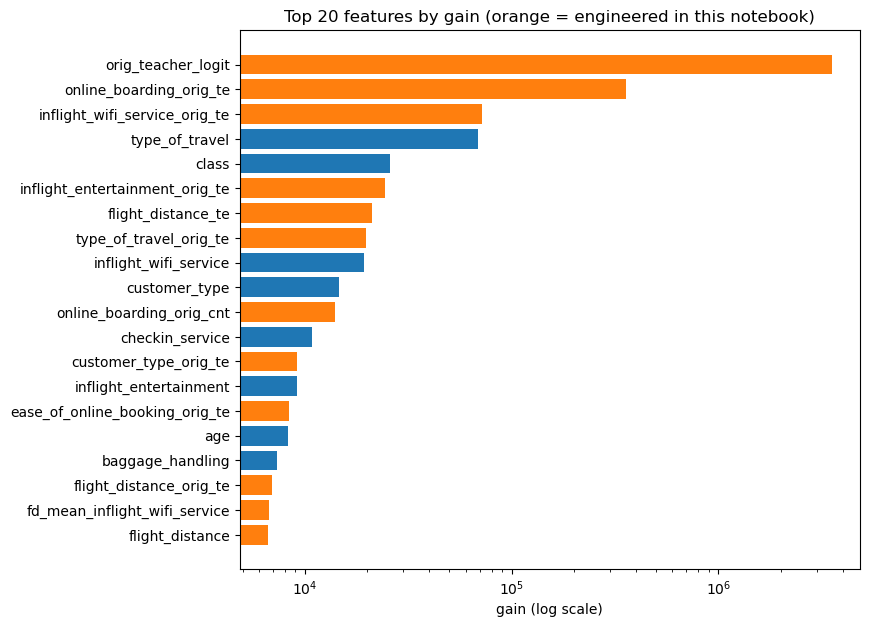

In [11]:
top = importance.sort_values(ascending=False).head(20)[::-1]
colors = ["#ff7f0e" if ("orig" in c or c.startswith("fd_") or c.startswith(ROUTE_KEY)) else "#1f77b4" for c in top.index]
plt.figure(figsize=(8, 7))
plt.barh(top.index, top.values, color=colors)
plt.xscale("log")
plt.xlabel("gain (log scale)")
plt.title("Top 20 features by gain (orange = engineered in this notebook)")
plt.show()

In [12]:
sub = pd.DataFrame({"id": test["id"], TARGET: test_pred})
sub.to_csv("submission.csv", index=False)
sub.head()

,id,satisfaction
0,699635,0.217691
1,699636,0.691235
2,699637,0.902545
3,699638,0.075643
4,699639,0.047680


## 6. What I did on top of this (not run here)

| Step | CV | Private |
|---|---|---|
| Same features with **XGBoost** and **CatBoost**, rank-averaged with this LightGBM (weights searched on OOF, checked by nested CV) | 0.96101 | 0.96129 |
| All three models retrained with **10 folds** (more data per model; CV evaluated on the same 5-fold split) | 0.96116 | 0.96137 |
| + a 4th model: **CatBoost with 39 crosses** "rating × Class / Type of Travel / Customer Type" as categorical features ([#745892](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/745892)) | **0.96121** | **0.96140** |

Notes:

* With the richer features the three GBDTs disagree more (OOF correlation 0.982–0.986 vs. 0.998+ on raw features), which is why the ensemble helps.
* The crosses barely changed CatBoost's own CV (+0.00001), but its OOF correlation with the plain CatBoost was only 0.989, so it still helped the blend.
* ⚠️ With 43 categorical columns, set CatBoost's **`max_ctr_complexity=1`**. With the default, a 50k-row sample did not finish in 30 minutes.

## 7. What did not work

| Idea | Δ CV |
|---|---|
| Flags / row statistics for rating = 0 | −0.00017 |
| Appending the original rows to the training data | −0.00020 |
| Residuals "row value − route mean" | −0.00026 |

Thanks for reading! If you found this useful, an upvote is much appreciated. Questions and suggestions are welcome in the comments. 🙌